# 04 — Does the model generalize, or recognize measurement patterns?

The previous forest used 48 features and scenario-grouped CV. Before
adding complexity, we test two feature ablations and a harder split.
This notebook reruns the entire fixed audit. The data has already been
explored: this is a diagnostic study, not a fresh final test.
Read `docs/ROBUSTNESS_PROTOCOL.md` for the pre-run specification.

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from rca.robustness import OUTPUT_DIR, REFERENCE, AVAILABILITY, BEHAVIOR, run_experiment
from rca.robustness_report import overall_table, plot_audit, build_report
print('Availability features:', len(AVAILABILITY), '| behavior features:', len(BEHAVIOR))
display(pd.DataFrame({'availability_only': pd.Series(AVAILABILITY),
                      'behavior_only': pd.Series(BEHAVIOR)}))

Availability features: 8 | behavior features: 24


,availability_only,behavior_only
0,cpu__available,cpu__signed_log_shift
1,mem__available,cpu__relative_shift
2,load__available,cpu__log_std_ratio
3,workload__available,mem__signed_log_shift
4,error__available,mem__relative_shift
5,latency__available,mem__log_std_ratio
6,latency-50__available,load__signed_log_shift
7,latency-90__available,load__relative_shift
8,NaN,load__log_std_ratio
9,NaN,workload__signed_log_shift


## 1. Fix the question before fitting

Availability-only uses eight finite-observation flags, without change
values. Behavior-only uses 24 shift/variability features, without explicit
availability/constant/onset flags. Both use the exact original scenario
folds and the same forest settings. Missing-feature zeros can still
expose schema, so behavior-only is not guaranteed shortcut-free.

The harder task holds out all incidents rooted at one service, across
every fault family and repetition. That service can still occur as a
negative candidate in training. This tests a new fault location inside
Online Boutique, not an entirely unseen service or application.

In [2]:
cases, summary, folds = run_experiment()
manifest = json.loads((OUTPUT_DIR / 'manifest.json').read_text())
source = pd.read_csv('results/supervised/incidents.csv').set_index('case_id')
split_rows = []
for variant in manifest['variants']:
    tested = []
    for fold in variant['folds']:
        train_ids, test_ids = fold['train_case_ids'], fold['test_case_ids']
        assert not set(train_ids) & set(test_ids)
        if variant['method'] == 'held_out_root':
            assert not source.loc[train_ids, 'true_root'].eq(fold['held_out_root']).any()
            assert source.loc[test_ids, 'true_root'].eq(fold['held_out_root']).all()
        else:
            assert not set(source.loc[train_ids, 'scenario_group']) & set(source.loc[test_ids, 'scenario_group'])
        tested.extend(test_ids)
        split_rows.append({'experiment': variant['method'], 'fold': fold['fold'],
                           'train_incidents': len(train_ids), 'test_incidents': len(test_ids),
                           'held_out_root': fold.get('held_out_root', '')})
    assert len(tested) == len(set(tested)) == 123
display(pd.DataFrame(split_rows))

availability_only, fold 1: train 98, test 25, features 8


availability_only, fold 2: train 98, test 25, features 8


availability_only, fold 3: train 98, test 25, features 8


availability_only, fold 4: train 99, test 24, features 8


availability_only, fold 5: train 99, test 24, features 8


...

held_out_root, fold 3: train 98, test 25, features 48


held_out_root, fold 4: train 99, test 24, features 48


held_out_root, fold 5: train 99, test 24, features 48


                   method  n_cases     AC@1     AC@3     AC@5    Avg@5
        availability_only      123 0.276423 0.634146 0.756098 0.580488
            behavior_only      123 0.926829 0.951220 0.991870 0.956098
full_features_scenario_cv      123 0.918699 0.959350 0.991870 0.960976
            held_out_root      123 0.934959 0.975610 1.000000 0.972358


,experiment,fold,train_incidents,test_incidents,held_out_root
0,availability_only,1,98,25,
1,availability_only,2,98,25,
2,availability_only,3,98,25,
3,availability_only,4,99,24,
4,availability_only,5,99,24,
5,behavior_only,1,98,25,
6,behavior_only,2,98,25,
7,behavior_only,3,98,25,
8,behavior_only,4,99,24,
9,behavior_only,5,99,24,


## 2. Show every result, including regressions

The first three rows share identical folds; the last row changes the
training task. We report per-incident root ranks, not binary accuracy
over mostly negative candidates. The two invalid recordings stay as
explicit misses in the all-125 table. No subset is chosen as a winner.

,Experiment,Incidents,AC@1,AC@3,AC@5,Avg@5
0,Full features / scenario CV (reference),123,91.87%,95.93%,99.19%,96.10%
1,Availability only / same scenario CV,123,27.64%,63.41%,75.61%,58.05%
2,Behavior only / same scenario CV,123,92.68%,95.12%,99.19%,95.61%
3,Full features / held-out root service,123,93.50%,97.56%,100.00%,97.24%


,Experiment,Incidents,AC@1,AC@3,AC@5,Avg@5
0,Full features / scenario CV (reference),125,90.40%,94.40%,97.60%,94.56%
1,Availability only / same scenario CV,125,27.20%,62.40%,74.40%,57.12%
2,Behavior only / same scenario CV,125,91.20%,93.60%,97.60%,94.08%
3,Full features / held-out root service,125,92.00%,96.00%,98.40%,95.68%


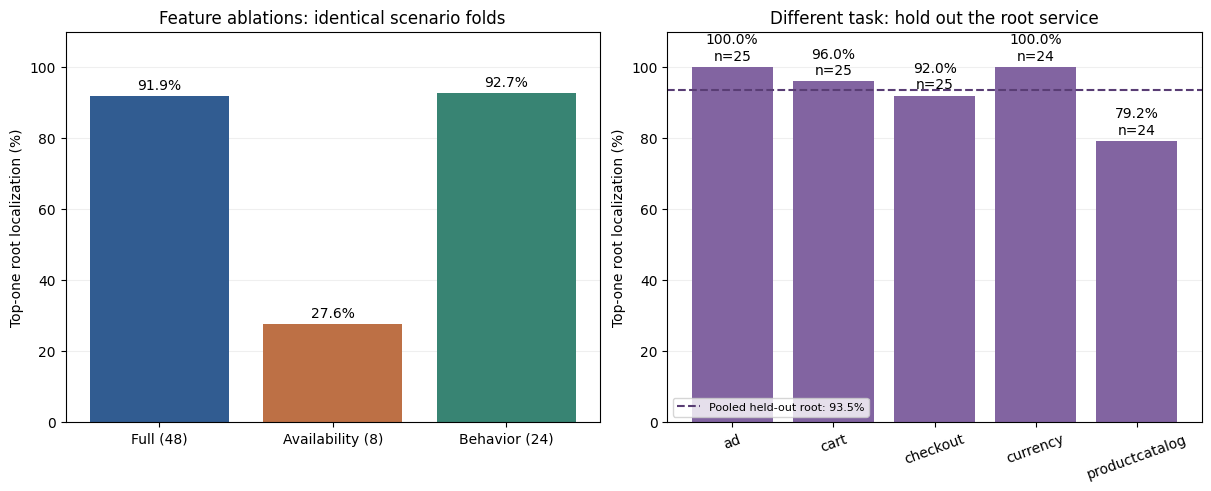

,held_out_root,n_cases,AC@1,AC@3,AC@5,Avg@5
15,adservice,25,1.000000,1.000,1.0,1.000000
16,cartservice,25,0.960000,1.000,1.0,0.992000
17,checkoutservice,25,0.920000,1.000,1.0,0.976000
18,currencyservice,24,1.000000,1.000,1.0,1.000000
19,productcatalogservice,24,0.791667,0.875,1.0,0.891667


In [3]:
display(overall_table(summary))
display(overall_table(summary, 'all_cases'))
figure = plot_audit(summary, folds)
plt.show()
display(folds.query("method == 'held_out_root'")[
    ['held_out_root', 'n_cases', 'AC@1', 'AC@3', 'AC@5', 'Avg@5']])

## 3. Inspect failures instead of hiding them in an average

Each score is produced by a model whose training incidents exclude that
test case. Availability-only performance is evidence that measurement
patterns contain predictive information; it does not prove label leakage
or causation. Root-service holdout is still within one application.

In [4]:
failures = cases.query("method == 'held_out_root' and status == 'ok' and rank_of_true_root > 1")
display(failures[['case_id', 'fault_type', 'held_out_root', 'rank_of_true_root']])
display(cases.query("method == 'held_out_root' and status != 'ok'")[['case_id', 'status', 'error']])
paired = pd.read_csv(OUTPUT_DIR / 'paired_ranks.csv')
for method in ['availability_only', 'behavior_only', 'held_out_root']:
    gains = int((paired[method].eq(1) & paired[REFERENCE].ne(1)).sum())
    losses = int((paired[method].ne(1) & paired[REFERENCE].eq(1)).sum())
    print(method, '| top-one gains vs reference:', gains, '| losses:', losses)

,case_id,fault_type,held_out_root,rank_of_true_root
415,re1ob_cartservice_loss_1,loss,cartservice,2.0
440,re1ob_checkoutservice_loss_1,loss,checkoutservice,3.0
441,re1ob_checkoutservice_loss_2,loss,checkoutservice,2.0
490,re1ob_productcatalogservice_loss_1,loss,productcatalogservice,5.0
491,re1ob_productcatalogservice_loss_2,loss,productcatalogservice,3.0
492,re1ob_productcatalogservice_loss_3,loss,productcatalogservice,4.0
493,re1ob_productcatalogservice_loss_4,loss,productcatalogservice,4.0
494,re1ob_productcatalogservice_loss_5,loss,productcatalogservice,2.0


,case_id,status,error
465,re1ob_currencyservice_loss_1,invalid_window,Feature extraction needs >=2 normal and >=1 an...
477,re1ob_productcatalogservice_cpu_3,invalid_window,Feature extraction needs >=2 normal and >=1 an...


availability_only | top-one gains vs reference: 1 | losses: 80
behavior_only | top-one gains vs reference: 1 | losses: 0
held_out_root | top-one gains vs reference: 3 | losses: 1


## 4. Interpretation and evidence

All settings are fixed. These data have already informed project design,
so additional decisions based on this audit remain exploratory. No
confidence interval, causal effect, online detection, or cross-system
result is claimed. The next step is to reserve genuinely new data and
specify that evaluation before further model selection. Short observation
windows, robust statistics, and recording-regime sensitivity remain open.

`scripts/verify_project.py` independently refits all 15 new forests,
verifies candidate scores, rankings, split isolation, hashes and metrics.

In [5]:
report = build_report()
print('Saved docs/ROBUSTNESS_AUDIT.md, figure, full scores, folds and failures.')

Saved docs/ROBUSTNESS_AUDIT.md, figure, full scores, folds and failures.
